In [2]:
from google.colab import files
uploaded=files.upload()

Saving Week_4_Messy_Housing_Data_2000_092715 - Week_4_Messy_Housing_Data_2000_092715.csv to Week_4_Messy_Housing_Data_2000_092715 - Week_4_Messy_Housing_Data_2000_092715.csv


In [3]:
import os

# Define current and target file names
current_name = 'Week_4_Messy_Housing_Data_2000_092715 - Week_4_Messy_Housing_Data_2000_092715.csv'
target_name = 'Week_4_Messy_Housing_Data_2000_092715.csv'

# Rename the file if it exists
if os.path.exists(current_name):
    os.rename(current_name, target_name)
    print(f"Successfully renamed file to: {target_name}")
else:
    print(f"Could not find '{current_name}' in the current directory.")

Successfully renamed file to: Week_4_Messy_Housing_Data_2000_092715.csv


In [4]:
import pandas as pd
df=pd.read_csv("Week_4_Messy_Housing_Data_2000_092715.csv")

In [5]:
df['Property_ID'].duplicated().sum()

np.int64(100)

In [6]:
print("Shape:", df.shape)
print("Columns: ", list(df.columns))
print("Missing values:", (df.isnull().sum()))
print("Duplicate values: ", df.duplicated().sum())
#Understanding the duplicates' nature
columns = [
    'Property_ID', 'Location', 'Property_Type', 'Size_SqFt',
    'Bedrooms', 'Bathrooms', 'Garage_Spaces', 'Property_Age_Years',
    'Distance_City_Center_Km', 'Has_Garden', 'House_Price'
]

for col in columns:
    count = df[col].duplicated().sum()
    print(f"Duplicate {col}: {count}")
df.loc[
    df['Property_ID'].duplicated(keep=False),
    'Property_ID'
].nunique()
df['Property_ID'].value_counts().value_counts().sort_index()
df[df['Property_ID'].duplicated(keep=False)].sort_values('Property_ID')
#Isolating the sources of the main duplicates
duplicate_rows = df[
    df['Property_ID'].duplicated(keep=False)
]

print(duplicate_rows.groupby('Property_ID').nunique())
df = df.drop_duplicates('Property_ID')

df['Location']=df['Location'].str.strip().str.title()
df['Location'].isna().sum()
df['Location'].value_counts()

df['Location'] = df['Location'].replace(r'^\s*$', pd.NA, regex=True)

print(df['Location'].isna().sum())
#Filling Location with the mode
mode_location = df['Location'].mode()[0]

df['Location'] = df['Location'].fillna(mode_location)

print("Mode:", mode_location)
print("Missing values remaining:", df['Location'].isna().sum())
#Unto the next
df['Property_Type'] = df['Property_Type'].str.strip().str.title()
df['Property_Type'] = df['Property_Type'].replace(r'^\s*$', pd.NA, regex=True)
print('Missing values(Property_Type)=16')
df['Property_Type'].value_counts()

# Doing the work for filling the Property_types as accurately as possible
pd.crosstab(
    df['Bedrooms'],
    df['Property_Type']
)


pd.crosstab(
    [df['Location'], df['Bedrooms']],
    df['Property_Type']
)


# Get rows where Property_Type is known
known = df[df['Property_Type'].notna()].copy()

Shape: (2000, 11)
Columns:  ['Property_ID', 'Location', 'Property_Type', 'Size_SqFt', 'Bedrooms', 'Bathrooms', 'Garage_Spaces', 'Property_Age_Years', 'Distance_City_Center_Km', 'Has_Garden', 'House_Price']
Missing values: Property_ID                 0
Location                   24
Property_Type              18
Size_SqFt                  30
Bedrooms                   18
Bathrooms                  23
Garage_Spaces              22
Property_Age_Years         18
Distance_City_Center_Km    25
Has_Garden                 20
House_Price                10
dtype: int64
Duplicate values:  63
Duplicate Property_ID: 100
Duplicate Location: 1981
Duplicate Property_Type: 1988
Duplicate Size_SqFt: 637
Duplicate Bedrooms: 1988
Duplicate Bathrooms: 1987
Duplicate Garage_Spaces: 1993
Duplicate Property_Age_Years: 1958
Duplicate Distance_City_Center_Km: 1751
Duplicate Has_Garden: 1992
Duplicate House_Price: 1054
             Location  Property_Type  Size_SqFt  Bedrooms  Bathrooms  \
Property_ID            

In [7]:
#Cleaning the rest of the code to prep for the ML model to clean Property_Type
#Size_SqFt
df['Size_SqFt'] = (df['Size_SqFt'].astype('string').str.strip().str.replace(r'\s*sqft\s*$', '', regex=True, case=False))
df['Size_SqFt'] = pd.to_numeric(df['Size_SqFt'],errors='coerce')
#Verifying the cleaning
print(df['Size_SqFt'].dtype)
print(df['Size_SqFt'].head(10))
print("Missing sizes:", df['Size_SqFt'].isna().sum())

#Bedrooms
df['Bedrooms'] = (df['Bedrooms'].astype('string').str.strip().str.lower())
df['Bedrooms'] = df['Bedrooms'].replace({'one': '1','two': '2','three': '3','four': '4','five': '5','six': '6'})

df['Bedrooms'] = pd.to_numeric(df['Bedrooms'],
    errors='coerce'
)
df['Bedrooms'] = df['Bedrooms'].abs()
#Verification
print(df['Bedrooms'].value_counts(dropna=False).sort_index())
print(df['Bedrooms'].dtype)

#Bathrooms
df['Bathrooms'] = pd.to_numeric(df['Bathrooms'], errors='coerce')
df['Bathrooms'] = df['Bathrooms'].abs()
zero_bathroom_index=df[df['Bathrooms'] == 0.0].index
print(zero_bathroom_index)
#Verification
print(df['Bathrooms'].value_counts(dropna=False).sort_index())
print(df['Bathrooms'].dtype)

# Garage_Spaces
df['Garage_Spaces'] = df['Garage_Spaces'].replace({'one': '1','two': '2','three': '3','four': '4','five': '5','six': '6'})
df['Garage_Spaces'] = pd.to_numeric(df['Garage_Spaces'], errors='coerce')
#Verification
print(df['Garage_Spaces'].dtype)
print("Missing garage values:", df['Garage_Spaces'].isna().sum())
print(df['Garage_Spaces'].value_counts(dropna=False).sort_index())

# Property_Age_Years
# Clean the text values first before calling sort_index to avoid TypeError during sorting
df['Property_Age_Years'] = df['Property_Age_Years'].replace({'five': 5, 'new': 1})
df['Property_Age_Years'] = df['Property_Age_Years'].replace('10 years', 10)
df['Property_Age_Years'] = pd.to_numeric(df['Property_Age_Years'], errors='coerce')
df['Property_Age_Years'] = df['Property_Age_Years'].abs()
# Verification
print(df['Property_Age_Years'].value_counts(dropna=False).sort_index())
print(df['Property_Age_Years'].dtype)
print("Missing Property_Age values: ", df['Property_Age_Years'].isna().sum())

# Distance_City_Center_Km
print(df['Distance_City_Center_Km'].value_counts(dropna=False).sort_index())

df['Distance_City_Center_Km'] = (
    df['Distance_City_Center_Km']
    .astype('string')
    .str.strip()
    .str.replace(r'\s*km\s*$', '', regex=True, case=False)
)

df['Distance_City_Center_Km'] = pd.to_numeric(
    df['Distance_City_Center_Km'], errors='coerce'
)

# Verification
print(df['Distance_City_Center_Km'].dtype)
print(df['Distance_City_Center_Km'].head(10))
print("Missing distances:", df['Distance_City_Center_Km'].isna().sum())

#Has Garden
df['Has_Garden']=df['Has_Garden'].astype('string').str.strip().str.title()

# Has_Garden
df['Has_Garden'] = df['Has_Garden'].replace({
    'Y': 'Yes',
    'N': 'No'
})

# Verification
print(df['Has_Garden'].value_counts(dropna=False))
print('Missing values in Has_garden: ', df['Has_Garden'].isna().sum())

#House_Price
df['House_Price'] = (
    df['House_Price']
    .astype('string')
    .str.strip()
    .str.replace(r'\s*NGN\s*$', '', regex=True, case=False)
)

df['House_Price'] = pd.to_numeric(
    df['House_Price'], errors='coerce'
)

#Verification
print(df['House_Price'].value_counts(dropna=False))

print(df['House_Price'].unique())

print("Missing values in House_Price: ", df['House_Price'].isna().sum())


Int64
0    2432
1    2469
2    2650
3    2681
4    1186
5    1571
6    1052
7    1197
8    1382
9    2913
Name: Size_SqFt, dtype: Int64
Missing sizes: 27
Bedrooms
1       304
2       328
3       318
4       301
5       318
6       311
15        1
<NA>     19
Name: count, dtype: Int64
Int64
Index([928], dtype='int64')
Bathrooms
0.0       1
1.0     299
2.0     336
3.0     306
4.0     301
5.0     321
6.0     247
7.0      59
18.0      1
NaN      29
Name: count, dtype: int64
float64
float64
Missing garage values: 24
Garage_Spaces
0.0    374
1.0    866
2.0    503
3.0    133
NaN     24
Name: count, dtype: int64
Property_Age_Years
0.0      58
1.0      69
2.0      48
3.0      46
4.0      61
5.0      58
6.0      48
7.0      48
8.0      59
9.0      53
10.0     48
11.0     51
12.0     42
13.0     53
14.0     47
15.0     53
16.0     42
17.0     59
18.0     59
19.0     54
20.0     52
21.0     54
22.0     43
23.0     64
24.0     50
25.0     51
26.0     45
27.0     44
28.0     40
29.0     54
30.0     

In [11]:
# Now time for the cool stuff.
# We are using a ML model to find out if there are patterns in other columns that help determine what property type a property turns out to be

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Split into known and missing property types
known_data = df[df['Property_Type'].notna()].copy()
missing_data = df[df['Property_Type'].isna()].copy()

# Identify column types
numerical_columns = [
    'Size_SqFt',
    'Bedrooms',
    'Bathrooms',
    'Garage_Spaces',
    'Property_Age_Years',
    'Distance_City_Center_Km',
    'House_Price'
]

categorical_columns = [
    'Location',
    'Has_Garden'
]

# Define features (X) and target (y) for the known data
# We convert experimental pandas nullable types to standard float/object types with np.nan
# to prevent scikit-learn from encountering 'pd.NA'
X = known_data[numerical_columns + categorical_columns].copy()
for col in X.columns:
    if col in numerical_columns:
        X[col] = X[col].astype(float)
    else:
        X[col] = X[col].astype(object).fillna(np.nan)

y = known_data['Property_Type']

# Handle missing numerical values using the median
numerical_preprocessor = SimpleImputer(strategy='median')

# Handle missing categorical values and convert text to numbers
categorical_preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Apply the correct preprocessing to each type of column
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_preprocessor, numerical_columns),
    ('cat', categorical_preprocessor, categorical_columns)
])
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Build the complete model
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

# Train the model
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Use every row with a known Property_Type for final training
X_all = known_data[numerical_columns + categorical_columns].copy()
for col in X_all.columns:
    if col in numerical_columns:
        X_all[col] = X_all[col].astype(float)
    else:
        X_all[col] = X_all[col].astype(object).fillna(np.nan)
y_all = known_data['Property_Type']

model.fit(X_all, y_all)

# Prepare the rows with missing Property_Type
X_missing = missing_data[numerical_columns + categorical_columns].copy()
for col in X_missing.columns:
    if col in numerical_columns:
        X_missing[col] = X_missing[col].astype(float)
    else:
        X_missing[col] = X_missing[col].astype(object).fillna(np.nan)

# Predict their property types
predictions = model.predict(X_missing)

# View the predictions alongside the property details
results = missing_data[['Property_ID']].copy()
results['Predicted_Property_Type'] = predictions

print(results)

# Filling the blank cells in Property_Type with the predicted values
predictions_dict = dict(zip(results['Property_ID'], results['Predicted_Property_Type']))

df['Property_Type'] = df.apply(
    lambda row: predictions_dict.get(row['Property_ID'], row['Property_Type']),
    axis=1
)

# Cross-checking the whole dataset
print(df.isna().sum())

Accuracy: 0.4350132625994695
              precision    recall  f1-score   support

   Apartment       0.56      0.66      0.61        96
    Bungalow       0.30      0.32      0.31        79
    Detached       0.30      0.29      0.29        66
      Duplex       0.53      0.62      0.57        79
     Terrace       0.33      0.14      0.20        57

    accuracy                           0.44       377
   macro avg       0.40      0.40      0.39       377
weighted avg       0.42      0.44      0.42       377

     Property_ID Predicted_Property_Type
90         H0213                Bungalow
139        H1158               Apartment
149        H0122                 Terrace
326        H0155               Apartment
464        H0475                  Duplex
513        H1837               Apartment
580        H1493               Apartment
667        H0800                Detached
739        H1321                Bungalow
951        H0256               Apartment
1216       H0785               

In [12]:
#Filling all the missing values in the rest of the columns
# Count missing values in each column
print(df.isna().sum())

# Show only columns that contain missing values
print(df.isna().sum()[df.isna().sum() > 0])

# Total number of missing cells
print("Total missing values:", df.isna().sum().sum())


import numpy as np
import pandas as pd

from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split


# ============================================================
# 1. MAKE A WORKING COPY AND IDENTIFY THE COLUMNS
# ============================================================

df_before_imputation = df.copy(deep=True)
work = df.copy(deep=True)

for col in work.columns:
    work[col] = (
        work[col]
        .astype(object)
        .where(work[col].notna(), np.nan)
    )

# Support either British or American spelling of "Centre/Center".
distance_candidates = [
    'Distance_City_Centre_Km',
    'Distance_City_Center_Km'
]
distance_column = next(
    (col for col in distance_candidates if col in work.columns),
    None
)

numerical_columns = [
    'Size_SqFt',
    'Bedrooms',
    'Bathrooms',
    'Garage_Spaces',
    'Property_Age_Years',
    distance_column,
    'House_Price'
]

# Remove columns that do not exist in the dataset.
numerical_columns = [
    col for col in numerical_columns
    if col is not None and col in work.columns
]

categorical_columns = [
    col for col in ['Location', 'Has_Garden']
    if col in work.columns
]

# Convert numerical columns to numeric.
# Any unrecognized text becomes NaN and can be imputed.
for col in numerical_columns:
    work[col] = pd.to_numeric(
        work[col], errors='coerce'
    ).astype('float64')

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

print("\nMissing values before imputation:")
print(work.isna().sum())


# ============================================================
# 2. DEFINE THE IMPUTATION METHOD
# ============================================================

def make_numeric_imputer():
    return IterativeImputer(
        estimator=ExtraTreesRegressor(
            n_estimators=100,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ),
        max_iter=10,
        random_state=42,
        skip_complete=True
    )


# Count-like features should normally be whole numbers.
integer_columns = [
    col for col in [
        'Bedrooms',
        'Bathrooms',
        'Garage_Spaces',
        'Property_Age_Years'
    ]
    if col in numerical_columns
]

# These features cannot normally have negative values.
nonnegative_columns = [
    col for col in [
        'Size_SqFt',
        'Bedrooms',
        'Bathrooms',
        'Garage_Spaces',
        'Property_Age_Years',
        distance_column,
        'House_Price'
    ]
    if col is not None and col in numerical_columns
]


# ============================================================
# 3. TEST NUMERICAL IMPUTATION ON KNOWN VALUES
# ============================================================

# We temporarily hide some known values.
# The imputer must estimate those values without seeing them.

rng = np.random.default_rng(42)

validation_data = work[numerical_columns].copy()
original_values = work[numerical_columns].copy()

masked_positions = {}
for col in numerical_columns:
    observed_indices = original_values.index[
        original_values[col].notna()
    ]

    # Need enough known values to perform a useful test.
    if len(observed_indices) < 10:
        continue

    # Hide approximately 20% of known values.
    n_hide = max(1, int(len(observed_indices) * 0.20))

    hidden_indices = rng.choice(
        observed_indices.to_numpy(),
        size=n_hide,
        replace=False
    )

    masked_positions[col] = hidden_indices
    validation_data.loc[hidden_indices, col] = np.nan


# Fit using the artificially masked data.
# This evaluates the imputation method on values we know.
validation_imputer = make_numeric_imputer()

validation_array = validation_imputer.fit_transform(
    validation_data[numerical_columns]
)

validation_predictions = pd.DataFrame(
    validation_array,
    columns=numerical_columns,
    index=validation_data.index
)

# Apply realistic restrictions before evaluating.
for col in nonnegative_columns:
    validation_predictions[col] = validation_predictions[col].clip(lower=0)

for col in integer_columns:
    validation_predictions[col] = validation_predictions[col].round()


# Calculate validation metrics for each numerical column.
metric_rows = []

for col, hidden_indices in masked_positions.items():
    actual = original_values.loc[hidden_indices, col]
    predicted = validation_predictions.loc[hidden_indices, col]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    metric_rows.append({
        'Column': col,
        'Values tested': len(hidden_indices),
        'MAE': mae,
        'RMSE': rmse
    })

metrics_df = pd.DataFrame(metric_rows)

print("\nNUMERICAL IMPUTATION VALIDATION")
if not metrics_df.empty:
    print(metrics_df.round(3).to_string(index=False))
else:
    print("Not enough observed values to validate numerical imputation.")


# ============================================================
# 4. TEST CATEGORICAL IMPUTATION
# ============================================================

# Mode imputation is the fallback for categorical features.
# We test it by hiding some known categories and predicting
# them using the mode of the remaining observed values.

categorical_results = []

for col in categorical_columns:
    observed = work[col].dropna()

    if len(observed) < 10:
        continue

    n_hide = max(1, int(len(observed) * 0.20))

    hidden_indices = rng.choice(
        observed.index.to_numpy(),
        size=n_hide,
        replace=False
    )

    training_categories = work.loc[
        ~work.index.isin(hidden_indices), col
    ].dropna()

    if training_categories.empty:
        continue

    mode_values = training_categories.mode()

    if mode_values.empty:
        continue

    predicted_category = mode_values.iloc[0]
    actual_categories = work.loc[hidden_indices, col]

    accuracy = (
        actual_categories == predicted_category
    ).mean()

    categorical_results.append({
        'Column': col,
        'Values tested': n_hide,
        'Mode baseline accuracy': accuracy
    })

print("\nCATEGORICAL IMPUTATION VALIDATION")
if categorical_results:
    print(pd.DataFrame(categorical_results).round(3).to_string(index=False))
else:
    print("Not enough observed categories to validate mode imputation.")


# ============================================================
# 5. FIT THE FINAL NUMERICAL IMPUTER ON THE REAL DATA
# ============================================================

# This time, use the original missing values in work.
# Do not use the artificially masked validation_data.

numeric_imputer = make_numeric_imputer()

work[numerical_columns] = numeric_imputer.fit_transform(
    work[numerical_columns]
)

# Prevent negative estimates for nonnegative features.
for col in nonnegative_columns:
    work[col] = work[col].clip(lower=0)

# Round counts and ages to whole numbers.
for col in integer_columns:
    work[col] = work[col].round()

# If Bedrooms, Bathrooms and Garage_Spaces represent counts,
# rounding is appropriate. Property_Age_Years is also rounded
# here because the column represents whole years.


# ============================================================
# 6. IMPUTE CATEGORICAL COLUMNS
# ============================================================

for col in categorical_columns:

    # Normalize missing values before checking or imputing
    work[col] = (
        work[col]
        .astype(object)
        .where(work[col].notna(), np.nan)
    )

    if work[col].isna().any():

        if work[col].notna().sum() == 0:
            print(
                f"WARNING: {col} is entirely missing. "
                "It cannot be inferred from its own values."
            )
            continue

        categorical_imputer = SimpleImputer(
            strategy='most_frequent'
        )

        work[col] = categorical_imputer.fit_transform(
            work[[col]]
        ).ravel()

        print(f"Imputed missing values in {col}")


# ============================================================
# 7. REVIEW THE RESULTS BEFORE REPLACING df
# ============================================================

print("\nMissing values after imputation:")
print(work.isna().sum())

print("\nTotal missing cells remaining:", work.isna().sum().sum())

print("\nRows that originally had missing values:")
originally_missing_rows = df_before_imputation.isna().any(axis=1)

print(
    work.loc[originally_missing_rows].head(20).to_string(index=False)
)


# ============================================================
# 8. APPLY THE RESULTS TO df
# ============================================================

# Preserve the cleaned dataset's other columns and replace
# only the columns processed by this imputation workflow.
df[numerical_columns + categorical_columns] = work[
    numerical_columns + categorical_columns
]

print("\nImputation complete.")
print("Final shape:", df.shape)
print("Final missing cells:", df.isna().sum().sum())


Property_ID                 0
Location                    0
Property_Type               0
Size_SqFt                  27
Bedrooms                   19
Bathrooms                  29
Garage_Spaces              24
Property_Age_Years         16
Distance_City_Center_Km    26
Has_Garden                 17
House_Price                15
dtype: int64
Size_SqFt                  27
Bedrooms                   19
Bathrooms                  29
Garage_Spaces              24
Property_Age_Years         16
Distance_City_Center_Km    26
Has_Garden                 17
House_Price                15
dtype: int64
Total missing values: 173
Numerical columns: ['Size_SqFt', 'Bedrooms', 'Bathrooms', 'Garage_Spaces', 'Property_Age_Years', 'Distance_City_Center_Km', 'House_Price']
Categorical columns: ['Location', 'Has_Garden']

Missing values before imputation:
Property_ID                 0
Location                    0
Property_Type               0
Size_SqFt                  27
Bedrooms                   19
Bathro

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(



NUMERICAL IMPUTATION VALIDATION
                 Column  Values tested          MAE         RMSE
              Size_SqFt            374      231.110      332.916
               Bedrooms            376        0.418        0.824
              Bathrooms            374        0.468        0.729
          Garage_Spaces            375        0.629        0.879
     Property_Age_Years            376        9.202       10.943
Distance_City_Center_Km            374        6.351        7.615
            House_Price            377 12581669.476 16098971.735

CATEGORICAL IMPUTATION VALIDATION
    Column  Values tested  Mode baseline accuracy
  Location            380                   0.189
Has_Garden            376                   0.500
Imputed missing values in Has_Garden

Missing values after imputation:
Property_ID                0
Location                   0
Property_Type              0
Size_SqFt                  0
Bedrooms                   0
Bathrooms                  0
Garage_Spaces    

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [32]:
#Downloading the dataset to see how far
df.to_csv('Final_housing_data.csv', index=False)

from google.colab import files
files.download('Final_housing_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import pandas as pd

# Work on a copy so the original cleaned dataframe remains unchanged
df_encoded = df.copy()

# Convert garden availability to binary values
df_encoded["Has_Garden"] = (
    df_encoded["Has_Garden"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        "yes": 1,
        "y": 1,
        "true": 1,
        "1": 1,
        "no": 0,
        "n": 0,
        "false": 0,
        "0": 0
    })
)

# One-hot encode Location and Property_Type
df_encoded = pd.get_dummies(
    df_encoded,
    columns=["Location", "Property_Type"],
    dtype=int
)

# Check the result
print(df_encoded.head())
print("\nData types:")
print(df_encoded.dtypes)

print("\nRemaining missing values:")
print(df_encoded.isna().sum()[df_encoded.isna().sum() > 0])

  Property_ID  Size_SqFt  Bedrooms  Bathrooms  Garage_Spaces  \
0       H1093     2432.0       4.0        5.0            2.0   
1       H0075     2469.0       4.0        4.0            0.0   
2       H1851     2650.0       5.0        4.0            1.0   
3       H0300     2681.0       6.0        6.0            1.0   
4       H0973     1186.0       1.0        1.0            1.0   

   Property_Age_Years  Distance_City_Center_Km  Has_Garden  House_Price  \
0                 6.0                      5.1           0  104400000.0   
1                 3.0                      6.5           0   87200000.0   
2                 0.0                      8.9           0   89300000.0   
3                 2.0                      1.6           0  114800000.0   
4                29.0                     13.8           0   15400000.0   

   Location_Aba  Location_Asaba  Location_Awka  Location_Enugu  \
0             0               0              0               0   
1             1               0 

In [27]:
#Assignment: Predicting House prices
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 2. Select features (X) and target (y)
# We dynamically select all columns except the ID and target to include the newly one-hot encoded variables
feature_cols = [col for col in df_encoded.columns if col not in ["Property_ID", "House_Price"]]
X = df_encoded[feature_cols]

y = df_encoded["House_Price"]


# 3. Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# 4. Train the Linear Regression model

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)


# 5. Train the Random Forest model

forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train, y_train)


# 6. Make predictions

linear_predictions = linear_model.predict(X_test)
forest_predictions = forest_model.predict(X_test)


# 7. Evaluate both models

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }


results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, linear_predictions),
    evaluate_model("Random Forest", y_test, forest_predictions)
])

print(results.round(3).to_string(index=False))
# 8. Compare actual and predicted house prices

comparison = pd.DataFrame({
    "Actual Price (₦)": y_test,
    "Linear Regression (₦)": linear_predictions,
    "Random Forest (₦)": forest_predictions
})

print(
    comparison.head(10).round(0).map(
        lambda x: f"₦{x:,.0f}"
    ).to_string()
)

            Model         MAE        RMSE  R2 Score
Linear Regression 5904445.280 7443408.012     0.941
    Random Forest 7247561.413 9087026.931     0.913
     Actual Price (₦) Linear Regression (₦) Random Forest (₦)
1254      ₦54,000,000           ₦54,372,941       ₦56,302,500
111       ₦56,600,000           ₦58,514,352       ₦55,174,500
559       ₦82,800,000           ₦96,636,373       ₦85,869,500
531       ₦88,100,000           ₦93,198,753       ₦87,264,500
1348      ₦78,800,000           ₦85,292,255       ₦92,559,635
1125     ₦138,900,000          ₦136,883,080      ₦124,799,075
70        ₦78,600,000           ₦81,459,668       ₦81,194,000
251      ₦130,700,000          ₦127,745,187      ₦124,511,858
1352      ₦52,300,000           ₦52,541,214       ₦49,320,000
1050      ₦62,800,000           ₦70,738,776       ₦61,871,500


In [28]:
#Evaluating the model

# Calculate MSE from the existing predictions
linear_mse = mean_squared_error(y_test, linear_predictions)
forest_mse = mean_squared_error(y_test, forest_predictions)

# Retrieve RMSE and R² from the existing evaluation table
linear_row = results.loc[
    results["Model"] == "Linear Regression"
].iloc[0]

forest_row = results.loc[
    results["Model"] == "Random Forest"
].iloc[0]

# Combine the three metrics
evaluation = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MSE": [linear_mse, forest_mse],
    "RMSE": [linear_row["RMSE"], forest_row["RMSE"]],
    "R²": [linear_row["R2 Score"], forest_row["R2 Score"]]
})

print("MODEL EVALUATION")
print(evaluation.to_string(index=False))

# Interpret each model using the calculated results
for _, row in evaluation.iterrows():
    print(f"\n{row['Model']}")
    print(f"MSE: {row['MSE']:,.2f}")
    print(f"RMSE: ₦{row['RMSE']:,.2f}")
    print(f"R²: {row['R²']:.4f} ({row['R²'] * 100:.2f}%)")

    print(
        "Interpretation: "
        f"The model's RMSE indicates a typical prediction-error "
        f"scale of about ₦{row['RMSE']:,.2f}. "
        f"Its R² indicates that it explains "
        f"{row['R²'] * 100:.2f}% of the variation in house prices "
        "on the test set."
    )


MODEL EVALUATION
            Model          MSE         RMSE       R²
Linear Regression 5.540432e+13 7.443408e+06 0.941372
    Random Forest 8.257406e+13 9.087027e+06 0.912622

Linear Regression
MSE: 55,404,322,826,803.63
RMSE: ₦7,443,408.01
R²: 0.9414 (94.14%)
Interpretation: The model's RMSE indicates a typical prediction-error scale of about ₦7,443,408.01. Its R² indicates that it explains 94.14% of the variation in house prices on the test set.

Random Forest
MSE: 82,574,058,451,046.05
RMSE: ₦9,087,026.93
R²: 0.9126 (91.26%)
Interpretation: The model's RMSE indicates a typical prediction-error scale of about ₦9,087,026.93. Its R² indicates that it explains 91.26% of the variation in house prices on the test set.


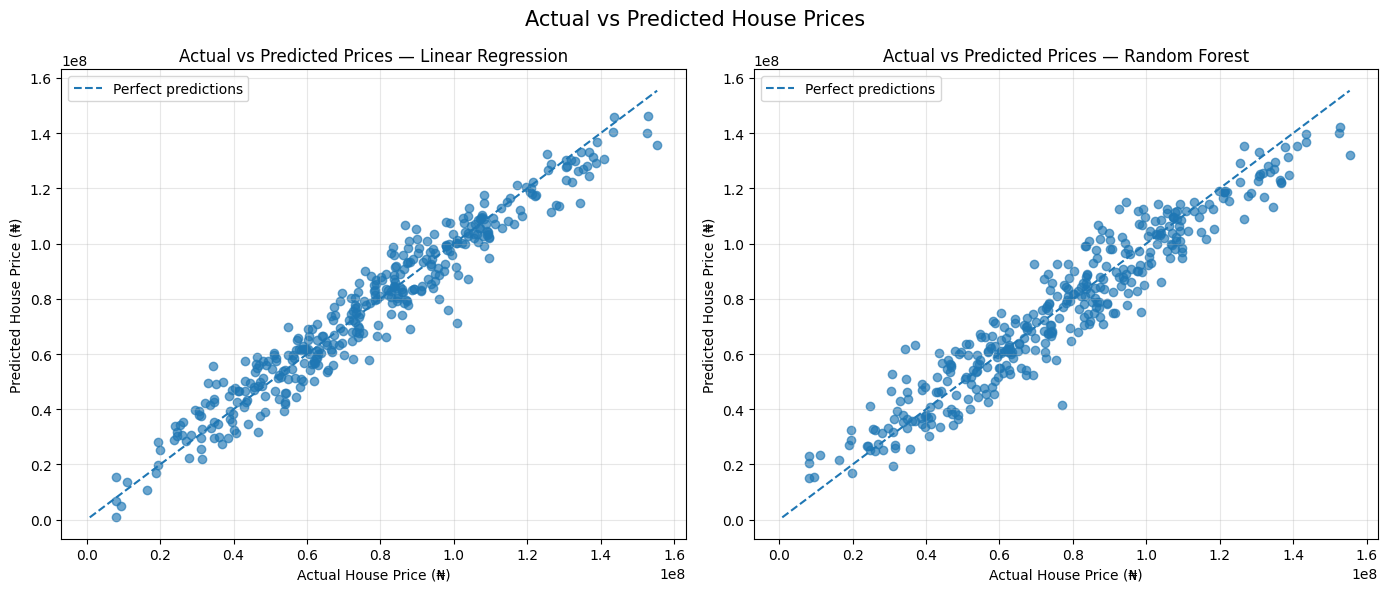


INTERPRETATION — ACTUAL VS PREDICTED

Each point represents a house in the test dataset.
The dashed diagonal line represents perfect predictions.
Points closer to this line indicate more accurate predictions.
Points above the line indicate overprediction, while points
below the line indicate underprediction.



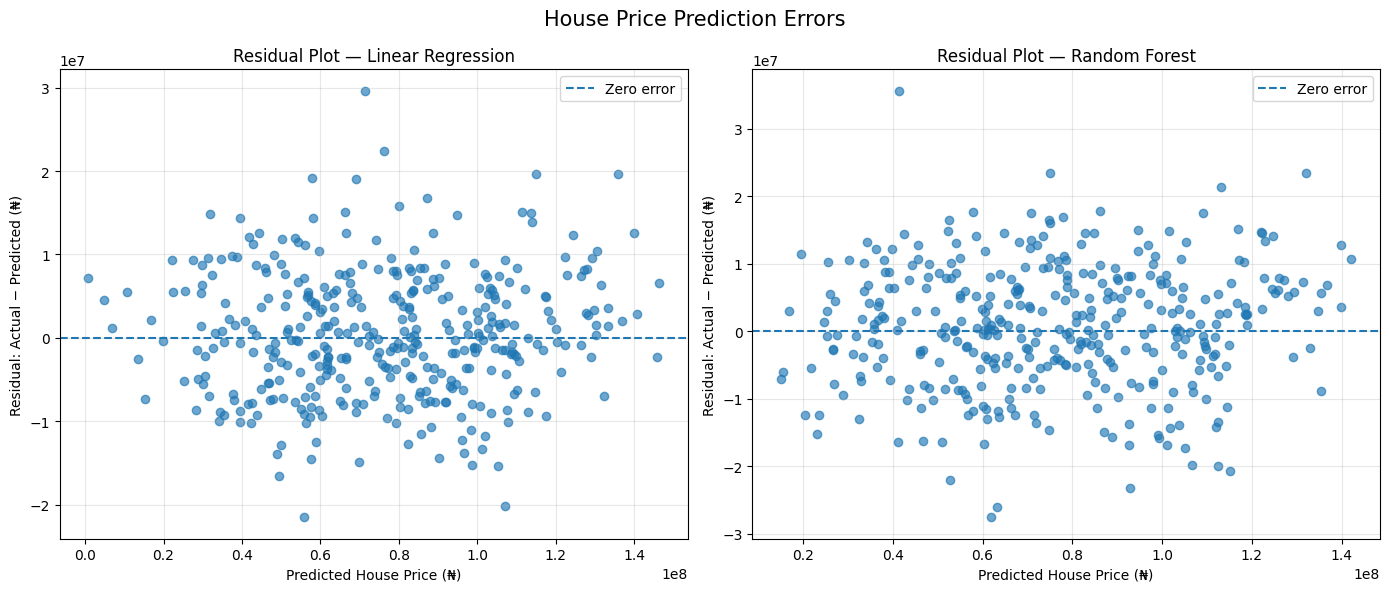


INTERPRETATION — RESIDUAL PLOTS

Residuals are calculated by subtracting predicted prices
from actual prices. Positive residuals indicate underprediction,
while negative residuals indicate overprediction.
Ideally, the points should be scattered around zero without
a clear pattern. Patterns or widening spreads may indicate
that the model struggles with certain houses or price ranges.


MODEL EVALUATION RESULTS
            Model                     MSE           RMSE     R²
Linear Regression 55,404,322,826,803.6328 7,443,408.0116 0.9414
    Random Forest 82,574,058,451,046.0469 9,087,026.9313 0.9126


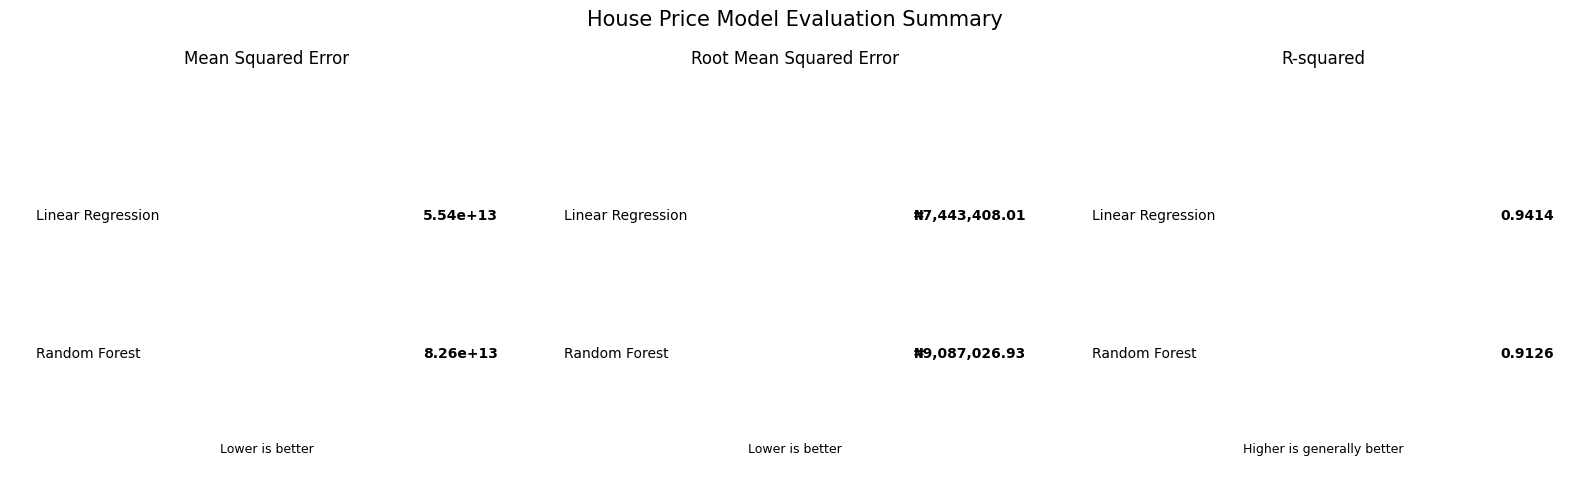


INTERPRETATION — MODEL EVALUATION

MSE measures the average squared prediction error.
RMSE expresses prediction error on the same currency scale
as house prices. Lower values generally indicate smaller errors.

R² measures how much variation in test-set house prices
is explained by the model relative to a mean-prediction baseline.
Higher values generally indicate better performance.

Compare all three metrics together. Do not compare the raw
MSE, RMSE, and R² values directly because they use different
scales and units.


Your chart files have been saved:
house_price_charts/actual_vs_predicted.png
house_price_charts/residual_error_plot.png
house_price_charts/model_evaluation_summary.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:

# ============================================
# HOUSE PRICE MODEL VISUALIZATIONS
# 1. Actual vs Predicted Prices
# 2. Residual/Error Plots
# 3. Model Evaluation Summary
# 4. Save charts as PNG and download them
# ============================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, r2_score
from google.colab import files

# --------------------------------------------
# STEP 1: PREPARE DATA
# --------------------------------------------

# Use existing test data and model predictions
actual = np.asarray(y_test)
linear_pred = np.asarray(linear_predictions)
forest_pred = np.asarray(forest_predictions)

# Folder where the PNG charts will be saved
output_folder = "house_price_charts"
os.makedirs(output_folder, exist_ok=True)

# Keep both models together for easier comparison
models = [
    ("Linear Regression", linear_pred),
    ("Random Forest", forest_pred)
]

# Common price range for the scatter plots
low = min(actual.min(), linear_pred.min(), forest_pred.min())
high = max(actual.max(), linear_pred.max(), forest_pred.max())


# --------------------------------------------
# CHART 1: ACTUAL VS PREDICTED PRICES
# --------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, predictions) in zip(axes, models):
    ax.scatter(actual, predictions, alpha=0.65)

    # Reference line: perfect predictions
    ax.plot(
        [low, high],
        [low, high],
        linestyle="--",
        label="Perfect predictions"
    )

    ax.set_title(f"Actual vs Predicted Prices — {name}")
    ax.set_xlabel("Actual House Price (₦)")
    ax.set_ylabel("Predicted House Price (₦)")
    ax.legend()
    ax.grid(True, alpha=0.3)

fig.suptitle("Actual vs Predicted House Prices", fontsize=15)
plt.tight_layout()

plt.savefig(
    f"{output_folder}/actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("""
INTERPRETATION — ACTUAL VS PREDICTED

Each point represents a house in the test dataset.
The dashed diagonal line represents perfect predictions.
Points closer to this line indicate more accurate predictions.
Points above the line indicate overprediction, while points
below the line indicate underprediction.
""")


# --------------------------------------------
# CHART 2: RESIDUAL / ERROR PLOTS
# --------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, predictions) in zip(axes, models):
    # Residual = Actual price - Predicted price
    residuals = actual - predictions

    ax.scatter(predictions, residuals, alpha=0.65)

    # Zero line represents no prediction error
    ax.axhline(
        y=0,
        linestyle="--",
        label="Zero error"
    )

    ax.set_title(f"Residual Plot — {name}")
    ax.set_xlabel("Predicted House Price (₦)")
    ax.set_ylabel("Residual: Actual − Predicted (₦)")
    ax.legend()
    ax.grid(True, alpha=0.3)

fig.suptitle("House Price Prediction Errors", fontsize=15)
plt.tight_layout()

plt.savefig(
    f"{output_folder}/residual_error_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("""
INTERPRETATION — RESIDUAL PLOTS

Residuals are calculated by subtracting predicted prices
from actual prices. Positive residuals indicate underprediction,
while negative residuals indicate overprediction.
Ideally, the points should be scattered around zero without
a clear pattern. Patterns or widening spreads may indicate
that the model struggles with certain houses or price ranges.
""")


# --------------------------------------------
# CHART 3: MODEL EVALUATION SUMMARY
# --------------------------------------------

evaluation = []

for name, predictions in models:
    mse = mean_squared_error(actual, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predictions)

    evaluation.append({
        "Model": name,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2
    })

evaluation = pd.DataFrame(evaluation)

print("\nMODEL EVALUATION RESULTS")
print(
    evaluation.to_string(
        index=False,
        float_format=lambda x: f"{x:,.4f}"
    )
)

# Create three separate panels because the metrics
# have different units and scales.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metric_info = [
    ("MSE", "Mean Squared Error"),
    ("RMSE", "Root Mean Squared Error"),
    ("R²", "R-squared")
]

for ax, (column, title) in zip(axes, metric_info):
    ax.axis("off")
    ax.set_title(title, fontsize=12, pad=18)

    for i, row in evaluation.iterrows():
        y_position = 0.68 - i * 0.35

        # Display model name
        ax.text(
            0.05,
            y_position,
            row["Model"],
            transform=ax.transAxes,
            fontsize=10,
            va="center"
        )

        # Format each metric appropriately
        if column == "MSE":
            value = f"{row[column]:,.2e}"
        elif column == "RMSE":
            value = f"₦{row[column]:,.2f}"
        else:
            value = f"{row[column]:.4f}"

        ax.text(
            0.95,
            y_position,
            value,
            transform=ax.transAxes,
            fontsize=10,
            ha="right",
            va="center",
            fontweight="bold"
        )

    # Explain which direction indicates better performance
    note = (
        "Lower is better"
        if column in ["MSE", "RMSE"]
        else "Higher is generally better"
    )

    ax.text(
        0.5,
        0.08,
        note,
        transform=ax.transAxes,
        ha="center",
        fontsize=9
    )

fig.suptitle("House Price Model Evaluation Summary", fontsize=15)
plt.tight_layout()

plt.savefig(
    f"{output_folder}/model_evaluation_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("""
INTERPRETATION — MODEL EVALUATION

MSE measures the average squared prediction error.
RMSE expresses prediction error on the same currency scale
as house prices. Lower values generally indicate smaller errors.

R² measures how much variation in test-set house prices
is explained by the model relative to a mean-prediction baseline.
Higher values generally indicate better performance.

Compare all three metrics together. Do not compare the raw
MSE, RMSE, and R² values directly because they use different
scales and units.
""")


# --------------------------------------------
# STEP 4: DOWNLOAD ALL THREE PNG FILES
# --------------------------------------------

print("\nYour chart files have been saved:")
print(f"{output_folder}/actual_vs_predicted.png")
print(f"{output_folder}/residual_error_plot.png")
print(f"{output_folder}/model_evaluation_summary.png")

# Download the three PNG files individually
files.download(f"{output_folder}/actual_vs_predicted.png")
files.download(f"{output_folder}/residual_error_plot.png")
files.download(f"{output_folder}/model_evaluation_summary.png")


In [31]:

import pandas as pd
import numpy as np

# ============================================
# 1. CREATE THREE IMAGINARY HOUSES
# ============================================

# Use actual category names from your dataset so that
# the new houses use valid locations and property types.
available_locations = (
    df["Location"].dropna().value_counts().index.tolist()
)

available_types = (
    df["Property_Type"].dropna().unique().tolist()
)

if len(available_locations) < 3:
    raise ValueError("Your dataset needs at least 3 known locations.")

if len(available_types) < 2:
    raise ValueError("Your dataset needs at least 2 property types.")

new_houses = pd.DataFrame([
    {
        "Location": available_locations[0],
        "Property_Type": available_types[0],
        "Size_SqFt": 1200,
        "Bedrooms": 2,
        "Bathrooms": 2,
        "Garage_Spaces": 1,
        "Property_Age_Years": 5,
        "Distance_City_Centre_Km": 3.0,
        "Has_Garden": df["Has_Garden"].dropna().unique()[0]
    },
    {
        "Location": available_locations[1],
        "Property_Type": available_types[1],
        "Size_SqFt": 2200,
        "Bedrooms": 4,
        "Bathrooms": 3,
        "Garage_Spaces": 2,
        "Property_Age_Years": 2,
        "Distance_City_Centre_Km": 8.0,
        "Has_Garden": df["Has_Garden"].dropna().unique()[-1]
    },
    {
        "Location": available_locations[2],
        "Property_Type": available_types[-1],
        "Size_SqFt": 1800,
        "Bedrooms": 3,
        "Bathrooms": 2,
        "Garage_Spaces": 1,
        "Property_Age_Years": 15,
        "Distance_City_Centre_Km": 12.0,
        "Has_Garden": df["Has_Garden"].dropna().unique()[0]
    }
])

print("NEW HOUSES")
display(new_houses)


# ============================================
# 2. APPLY THE SAME ENCODING APPROACH
# ============================================

# Encode categorical columns the same way as during training.
new_encoded = pd.get_dummies(
    new_houses,
    columns=["Location", "Property_Type"],
    dtype=int
)

# Convert Has_Garden using the mapping already used
# in df_encoded, based on the original row correspondence.
garden_mapping = (
    df[["Has_Garden"]]
    .join(df_encoded[["Has_Garden"]], rsuffix="_encoded")
    .dropna()
    .drop_duplicates()
    .set_index("Has_Garden")["Has_Garden_encoded"]
    .to_dict()
)

new_encoded["Has_Garden"] = new_encoded["Has_Garden"].map(
    garden_mapping
)

if new_encoded["Has_Garden"].isna().any():
    raise ValueError(
        "A garden value could not be mapped. "
        "Check the Has_Garden encoding used during training."
    )

# Use exactly the same feature columns and order as training.
# Missing dummy columns become 0; extra columns are discarded.
new_encoded = new_encoded.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Ensure features are numeric
new_encoded = new_encoded.astype(float)


# ============================================
# 3. PREDICT HOUSE PRICES
# ============================================

predicted_prices = linear_model.predict(new_encoded)

# Add predictions to the original house details
results_new_houses = new_houses.copy()

results_new_houses["Predicted_House_Price"] = predicted_prices

results_new_houses["Predicted_House_Price"] = (
    results_new_houses["Predicted_House_Price"]
    .round(2)
)

# Format the prices for easier reading
results_display = results_new_houses.copy()

results_display["Predicted_House_Price"] = (
    results_display["Predicted_House_Price"]
    .apply(lambda price: f"₦{price:,.2f}")
)

print("\nPREDICTED PRICES FOR NEW HOUSES")
display(results_display)


# ============================================
# 4. DISPLAY A CLEAN SUMMARY
# ============================================

for i, row in results_new_houses.iterrows():
    print(f"\nHouse {i + 1}")
    print("-" * 35)
    print(f"Location: {row['Location']}")
    print(f"Property Type: {row['Property_Type']}")
    print(f"Size: {row['Size_SqFt']:,} sq ft")
    print(f"Bedrooms: {row['Bedrooms']}")
    print(f"Bathrooms: {row['Bathrooms']}")
    print(f"Garage Spaces: {row['Garage_Spaces']}")
    print(f"Property Age: {row['Property_Age_Years']} years")
    print(
        "Distance from City Centre: "
        f"{row['Distance_City_Centre_Km']} km"
    )
    print(f"Has Garden: {row['Has_Garden']}")
    print(
        "Predicted Price: "
        f"₦{row['Predicted_House_Price']:,.2f}"
    )


NEW HOUSES


,Location,Property_Type,Size_SqFt,Bedrooms,Bathrooms,Garage_Spaces,Property_Age_Years,Distance_City_Centre_Km,Has_Garden
0,Aba,Detached,1200,2,2,1,5,3.0,No
1,Nnewi,Terrace,2200,4,3,2,2,8.0,Yes
2,Awka,Bungalow,1800,3,2,1,15,12.0,No



PREDICTED PRICES FOR NEW HOUSES


,Location,Property_Type,Size_SqFt,Bedrooms,Bathrooms,Garage_Spaces,Property_Age_Years,Distance_City_Centre_Km,Has_Garden,Predicted_House_Price
0,Aba,Detached,1200,2,2,1,5,3.0,No,"₦53,102,372.62"
1,Nnewi,Terrace,2200,4,3,2,2,8.0,Yes,"₦94,403,558.79"
2,Awka,Bungalow,1800,3,2,1,15,12.0,No,"₦55,425,826.92"



House 1
-----------------------------------
Location: Aba
Property Type: Detached
Size: 1,200 sq ft
Bedrooms: 2
Bathrooms: 2
Garage Spaces: 1
Property Age: 5 years
Distance from City Centre: 3.0 km
Has Garden: No
Predicted Price: ₦53,102,372.62

House 2
-----------------------------------
Location: Nnewi
Property Type: Terrace
Size: 2,200 sq ft
Bedrooms: 4
Bathrooms: 3
Garage Spaces: 2
Property Age: 2 years
Distance from City Centre: 8.0 km
Has Garden: Yes
Predicted Price: ₦94,403,558.79

House 3
-----------------------------------
Location: Awka
Property Type: Bungalow
Size: 1,800 sq ft
Bedrooms: 3
Bathrooms: 2
Garage Spaces: 1
Property Age: 15 years
Distance from City Centre: 12.0 km
Has Garden: No
Predicted Price: ₦55,425,826.92


## Phase 7: Short Model Interpretation

### 1. Features Used to Predict House Price

The model used the following features to predict house prices:

- Location
- Property type
- Size in square feet
- Number of bedrooms
- Number of bathrooms
- Number of garage spaces
- Property age in years
- Distance from the city centre
- Garden availability

`Property_ID` was excluded because it identifies each property rather than describing its characteristics. `House_Price` was used as the target variable.

### 2. Preprocessing Problems and Solutions

During data cleaning, I discovered missing values in some columns, including `Location` and `Property_Type`, as well as duplicate property IDs. I filled missing `Location` values using the mode and used a machine learning model to predict missing `Property_Type` values. I also handled other missing values using imputation where appropriate and encoded categorical features into numerical values so they could be used by the regression models. Duplicate IDs were investigated rather than automatically removing records, since duplicate identifiers do not always mean that every row is duplicated.

### 3. Model Evaluation

I compared Linear Regression and Random Forest using MSE, RMSE, and R².

Linear Regression achieved an MSE of approximately 55.40 trillion, an RMSE of ₦7.44 million, and an R² score of 0.9414. Random Forest achieved an MSE of approximately 82.57 trillion, an RMSE of ₦9.09 million, and an R² score of 0.9126.

Linear Regression performed better across all three metrics. Its R² score suggests that it explains approximately 94.14% of the variation in house prices in the test set. However, these results do not guarantee equally strong performance on all future properties.

### 4. Interpretation of the Plots

The actual-versus-predicted plots showed that both models captured the general relationship between property features and house prices, with many predictions lying relatively close to the perfect-prediction line. However, some predictions deviated noticeably from the line.

The residual plots showed errors on both sides of zero, indicating that the models sometimes overpredicted and sometimes underpredicted house prices. Some large residuals were also present, suggesting that certain properties were more difficult to predict accurately. The models may perform less consistently for particular price ranges or property characteristics.

### 5. Limitations of the Model and Dataset

The model's performance depends on the quality, size, and representativeness of the dataset. Missing values and imputed property types may introduce uncertainty. The dataset may also lack important factors affecting house prices, such as building condition, neighbourhood amenities, security, market demand, and recent property sales. In addition, the evaluation used a single train-test split, so the results may vary with different data splits. The predicted prices are estimates and should not be treated as confirmed market values.

### 6. Possible Improvements

Future improvements could include collecting more recent and representative housing data, investigating unusually large prediction errors, and adding more informative features. I could also use cross-validation to obtain a more reliable estimate of model performance, tune Random Forest's hyperparameters, and compare additional models such as Gradient Boosting. Finally, I would improve the preprocessing workflow by fitting imputers and encoders on the training data only, then applying them to the test data and new properties to reduce data leakage and ensure consistent encoding.